1. Importing libraries to begin exploratory data analysis of cleaned data. NumPy, Pandas, Matplotlib, seaborn, pathlib.

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

print("EDA environment ready!")

EDA environment ready!


2. Printing the clean dataset from data_cleaning_and_EDA draft.ipynb to check and reference for EDA.

In [2]:
data_path = Path("../data/cleaned/mumbai_rentals_refactored.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (20294, 22)


,Title,Price,Area,BHK,Bathrooms,Furnished,Balconies,Floor,Ownership,Facing,...,Property Type,Location,Year of Construction,Is Luxury,Description,Property Image,Invalid_Price,Suspicious_Area,Price_per_m2,Suspicious_Price
0,1BHK Multistorey Apartment for Rent in Bandra ...,70000.0,750.0,1.0,1.0,Furnished,NaN,7.0,Unknown,South -West,...,Apartment,Mumbai,2012.0,F,"1 BHK, Multistorey Apartment is available for ...",67249079_2_PropertyImage345-4855396928822.jpg,False,False,93.333333,False
1,3BHK Multistorey Apartment for Rent in Lodha N...,140000.0,1980.0,3.0,4.0,Unfurnished,4.0,21.0,Unknown,East,...,Apartment,Mumbai,1994.0,F,"3 BHK, Multistorey Apartment is available for ...",66155783_5_hatsAppImage20230217at13.56.28.jpeg,False,False,70.707071,False
2,3BHK Multistorey Apartment for Rent in Lodha P...,190000.0,1592.0,3.0,3.0,Unfurnished,1.0,20.0,Unknown,North - East,...,Apartment,Mumbai,NaN,F,"3 BHK, Multistorey Apartment is available for ...",66686709_1_HOTO20230407165614.jpg,False,False,119.346734,False
3,3BHK Multistorey Apartment for Rent in Rustomj...,110000.0,1305.0,3.0,3.0,Unfurnished,3.0,11.0,Freehold,West,...,Apartment,Mumbai,2010.0,F,"3 BHK, Multistorey Apartment is available for ...",67875387_1_PropertyImage559-8385323621333.jpg,False,False,84.291188,False
4,3BHK Multistorey Apartment for Rent in DLH The...,140000.0,1350.0,3.0,3.0,Unfurnished,NaN,29.0,Freehold,East,...,Apartment,Mumbai,2000.0,F,"3 BHK, Multistorey Apartment is available for ...",66670931_3_PropertyImage314-6685675359874.jpg,False,False,103.703704,False


3. Generating a histogram of monthly rental prices using seaborn and Matplotlib. This will help understand how rental prices are distributed across properties in the DataFrame.

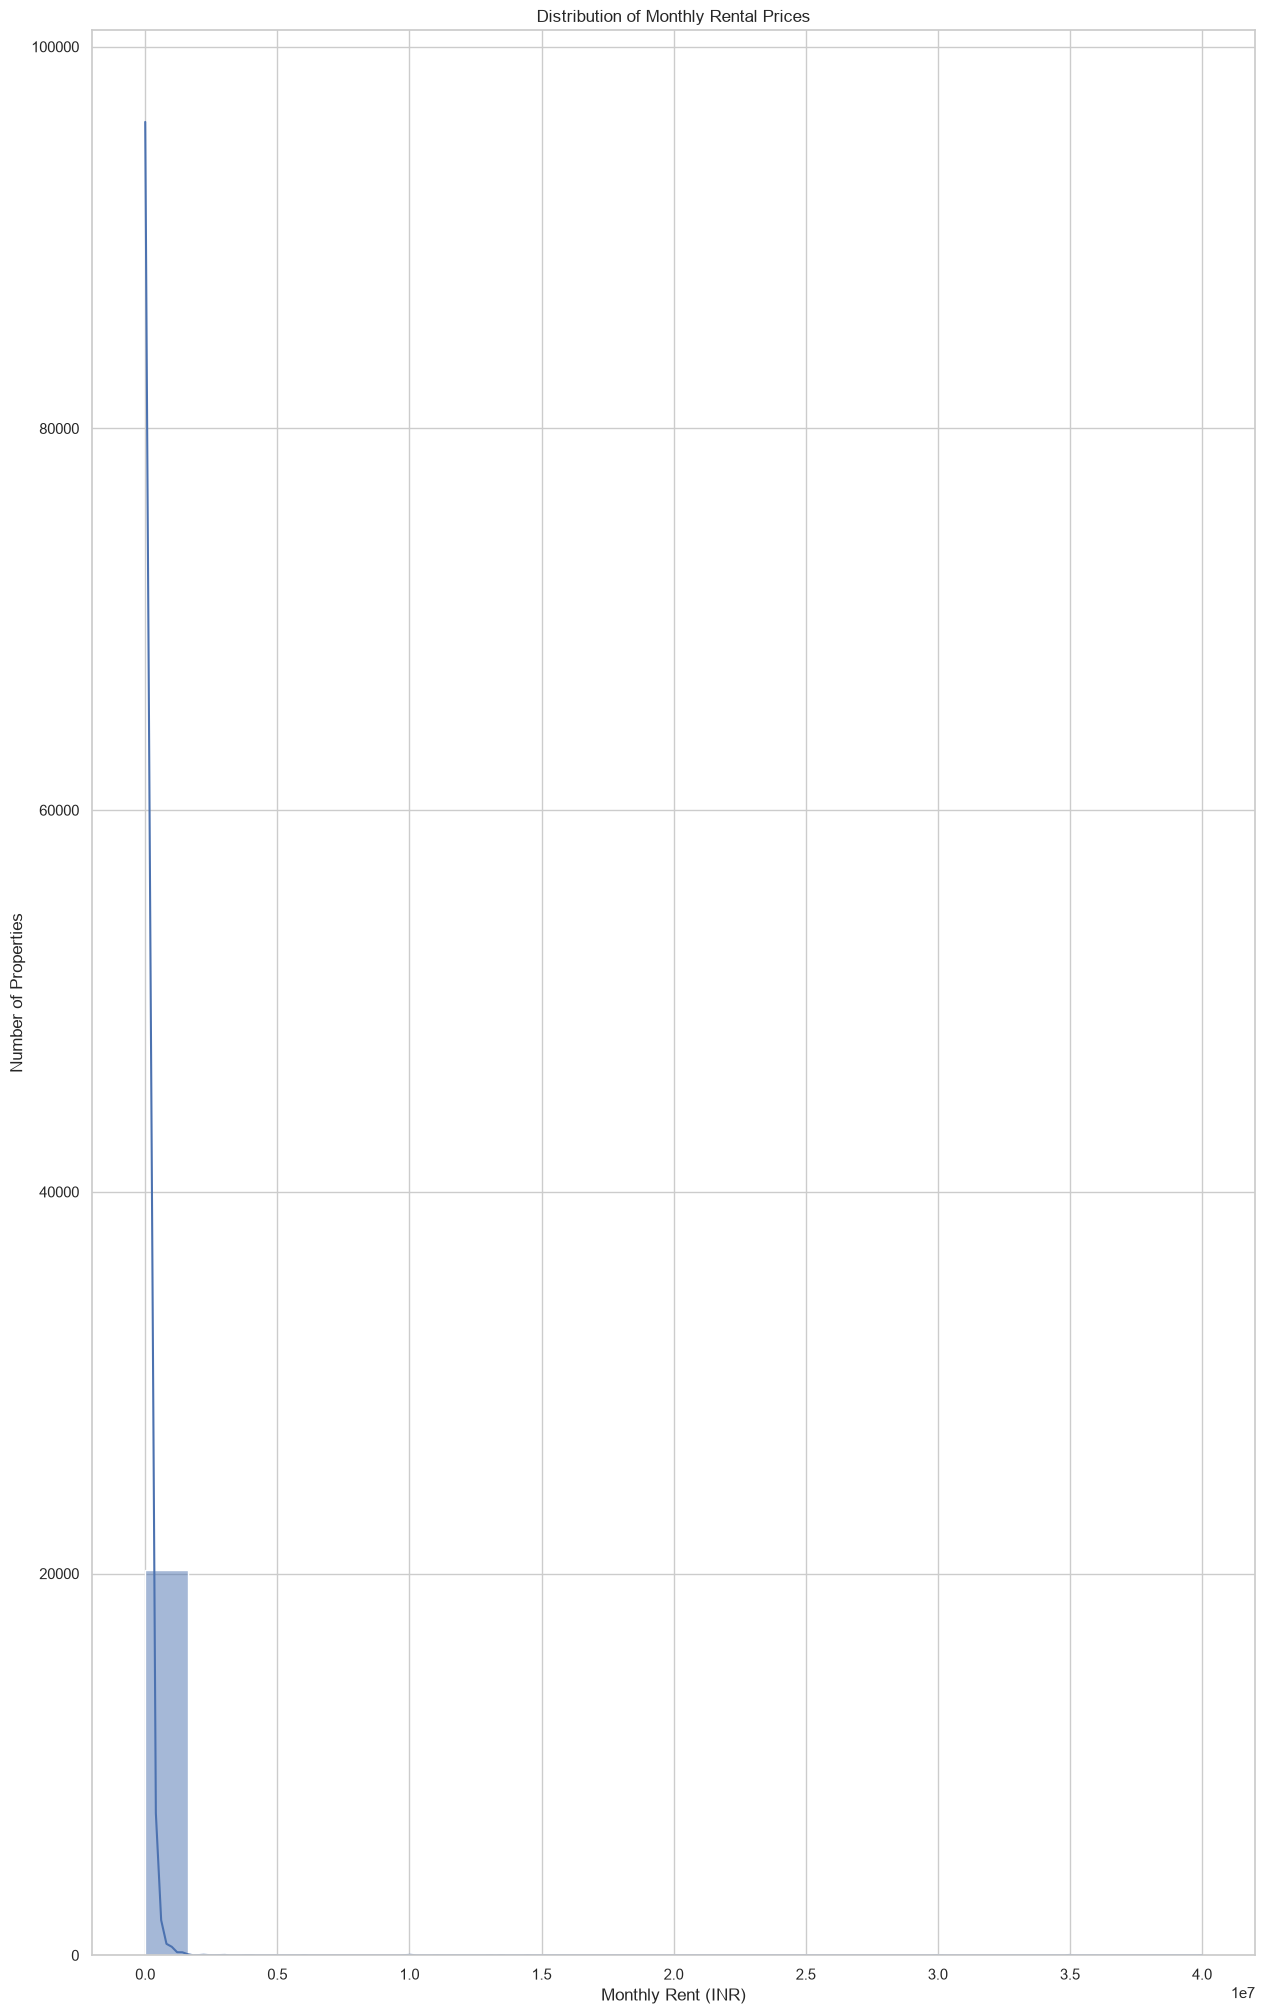

In [38]:
plt.figure(figsize=(15, 25))

sns.histplot(
    data=df,
    x="Price",
    bins=25,
    kde=True
)

plt.title("Distribution of Monthly Rental Prices")
plt.xlabel("Monthly Rent (INR)")
plt.ylabel("Number of Properties")
plt.show()

EDA 01: The graph is showing the distribution of monthly rental prices for the properties in the dataset. It helps us to understand the unusually high rental prices and understand whether there are any extreme outliers. A few extremely high prices stretch the graph across millions of rupees, which will be investigated further.

4. Calculating the mean and median monthly rent from DataFrame and visualizing a bar chart of the same.

Mean rent: ₹122,969
Median rent: ₹70,000


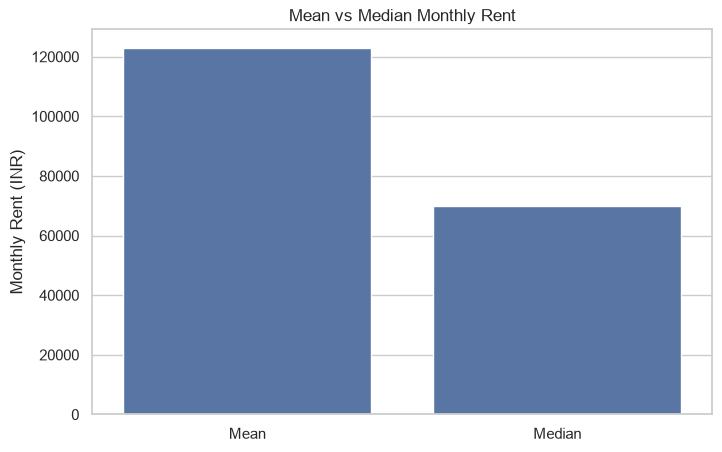

In [8]:
mean_rent = df["Price"].mean()
median_rent = df["Price"].median()

print(f"Mean rent: ₹{mean_rent:,.0f}")
print(f"Median rent: ₹{median_rent:,.0f}")

plt.figure(figsize=(8, 5))

sns.barplot(
    x=["Mean", "Median"],
    y=[mean_rent, median_rent]
)

plt.title("Mean vs Median Monthly Rent")
plt.ylabel("Monthly Rent (INR)")
plt.show()

EDA 02: Checking if unusually high rent prices are present that may affect the average rental prices.

5. Analyzing the relationship between property orientation and monthly reantal prices to check if factors such as vaastu or nature[sunlight, sea-facing, greenspaces, parkview, etc] have an influence.

Facing
East            9951
North - East    2780
Unknown         2612
West            1937
North           1399
South -West      707
North - West     405
South - East     272
South            231
Name: count, dtype: int64


,median,count
Facing,,
South -West,170000.0,707
South - East,160000.0,272
West,90000.0,1937
South,80000.0,231
North - East,75000.0,2779
North - West,75000.0,405
East,67000.0,9950
North,65000.0,1399
Unknown,40000.0,2515


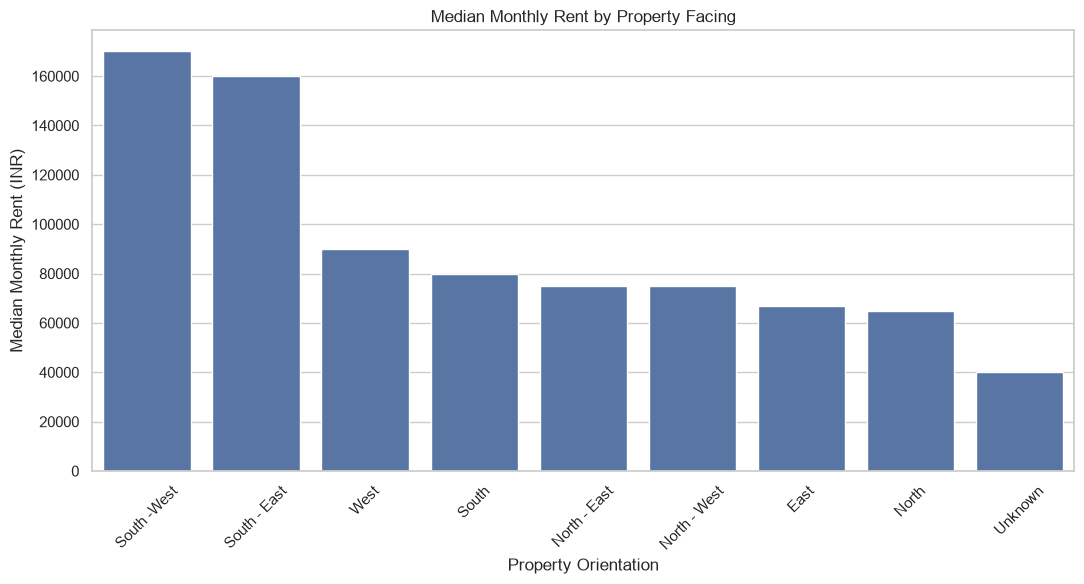

In [9]:
# Check available facing categories
print(df["Facing"].value_counts(dropna=False))

# Prepare data
facing_df = df[["Facing", "Price"]].copy()
facing_df["Price"] = pd.to_numeric(
    facing_df["Price"], errors="coerce"
)

facing_df["Facing"] = (
    facing_df["Facing"]
    .astype("string")
    .str.strip()
    .str.title()
)

facing_df = facing_df.dropna(subset=["Facing", "Price"])
# Calculate median rental price
facing_summary = (
    facing_df.groupby("Facing")["Price"]
    .agg(["median", "count"])
    .sort_values("median", ascending=False)
)
display(facing_summary)

# Create graph
plt.figure(figsize=(11, 6))
sns.barplot(
    data=facing_df,
    x="Facing",
    y="Price",
    estimator="median",
    errorbar=None,
    order=facing_summary.index
)

plt.title("Median Monthly Rent by Property Facing")
plt.xlabel("Property Orientation")
plt.ylabel("Median Monthly Rent (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

EDA 03: As per Vaastu [A scientific Indian system that zones out various spaces of a house based on cardinal directions]
North-east, North & East facing properties are considered auspicious, while south, south-west and west are not. 

However, in Mumbai - west, southwest and northwest balconies are provided for sea-facing properties which may lead to differences in conventional vaastu practices in the region.

6. Analyzing the monthly meadian rent with type of apartment: Furnished, Semi-Furnished and Unfurnished by generating a Bar graph.

['Title', 'Price', 'Area', 'BHK', 'Bathrooms', 'Furnished', 'Balconies', 'Floor', 'Ownership', 'Facing', 'Amenities', 'Transaction Type', 'Property Type', 'Location', 'Year of Construction', 'Is Luxury', 'Description', 'Property Image', 'Invalid_Price', 'Suspicious_Area', 'Price_per_m2', 'Suspicious_Price']


,count,mean,median
Furnished,,,
Furnished,5240,141364.539504,80000.0
Semi-Furnished,8739,138395.726399,80000.0
Unfurnished,6197,85925.550750,55000.0


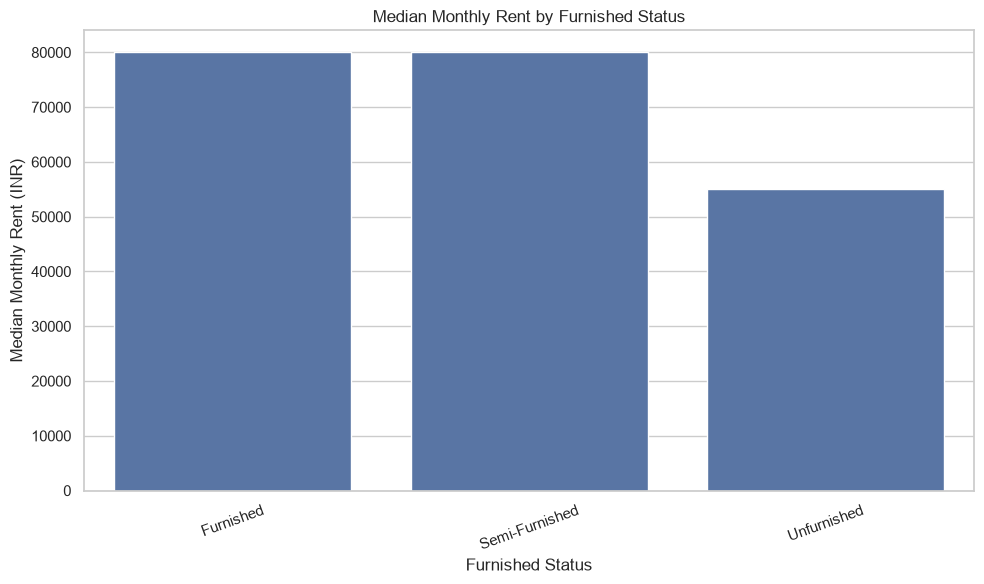

In [14]:
# Check the actual column names
print(df.columns.tolist())
# Change this if the dataset uses another column name
furnished_col = "Furnished"

# Prepare the data
furnished_df = df[[furnished_col, "Price"]].copy()
furnished_df["Price"] = pd.to_numeric(
    furnished_df["Price"], errors="coerce"
)

furnished_df[furnished_col] = (
    furnished_df[furnished_col]
    .astype("string")
    .str.strip()
    .str.title()
)

furnished_df = furnished_df.dropna(
    subset=[furnished_col, "Price"]
)

# Calculate summary statistics
furnished_summary = (
    furnished_df.groupby(furnished_col)["Price"]
    .agg(["count", "mean", "median"])
    .sort_values("median", ascending=False)
)

display(furnished_summary)
# Plot median monthly rent
plt.figure(figsize=(10, 6))

sns.barplot(
    data=furnished_df,
    x=furnished_col,
    y="Price",
    estimator="median",
    errorbar=None,
    order=furnished_summary.index
)

plt.title("Median Monthly Rent by Furnished Status")
plt.xlabel("Furnished Status")
plt.ylabel("Median Monthly Rent (INR)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

EDA 04: Furnished and Semi-furnished properties share an identical higher median monthly rent of appox. 80,000 INR. Unfurnished properties are lower median at appox.55,000INR

7. Analyzing the monthly mean rent with type of apartment: Furnished, Semi-Furnished and Unfurnished by generating a Bar graph.

,count,mean,median
Furnished,,,
Furnished,5240,141364.539504,80000.0
Semi-Furnished,8739,138395.726399,80000.0
Unfurnished,6197,85925.550750,55000.0


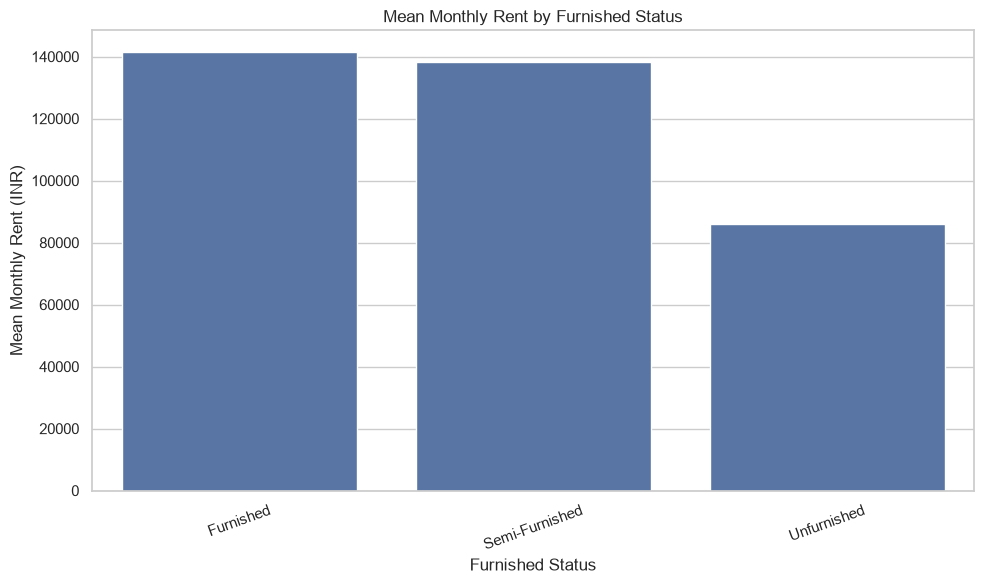

In [16]:
# Mean Rental Price by Furnishing Status
furnished_col = "Furnished"

# Prepare data
furnished_df = df[[furnished_col, "Price"]].copy()
furnished_df["Price"] = pd.to_numeric(
    furnished_df["Price"], errors="coerce"
)
furnished_df[furnished_col] = (
    furnished_df[furnished_col]
    .astype("string")
    .str.strip()
    .str.title()
)
furnished_df = furnished_df.dropna(
    subset=[furnished_col, "Price"]
)

# Calculate mean rental price
furnished_summary = (
    furnished_df.groupby("Furnished")["Price"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)
display(furnished_summary)

# Create bar chart
plt.figure(figsize=(10, 6))
sns.barplot(
    data=furnished_df,
    x="Furnished",
    y="Price",
    estimator="mean",
    errorbar=None,
    order=furnished_summary.index
)

plt.title("Mean Monthly Rent by Furnished Status")
plt.xlabel("Furnished Status")
plt.ylabel("Mean Monthly Rent (INR)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

EDA 05: Furnished and Semi-furnished properties have close mean monthly rent of appox. 1,30,000 INR to 1,45,000INR. Unfurnished properties are lower mean at appox.85,000INR.

8. Comparing the rental prices over the years with type of furnishing using a scatter plot. 

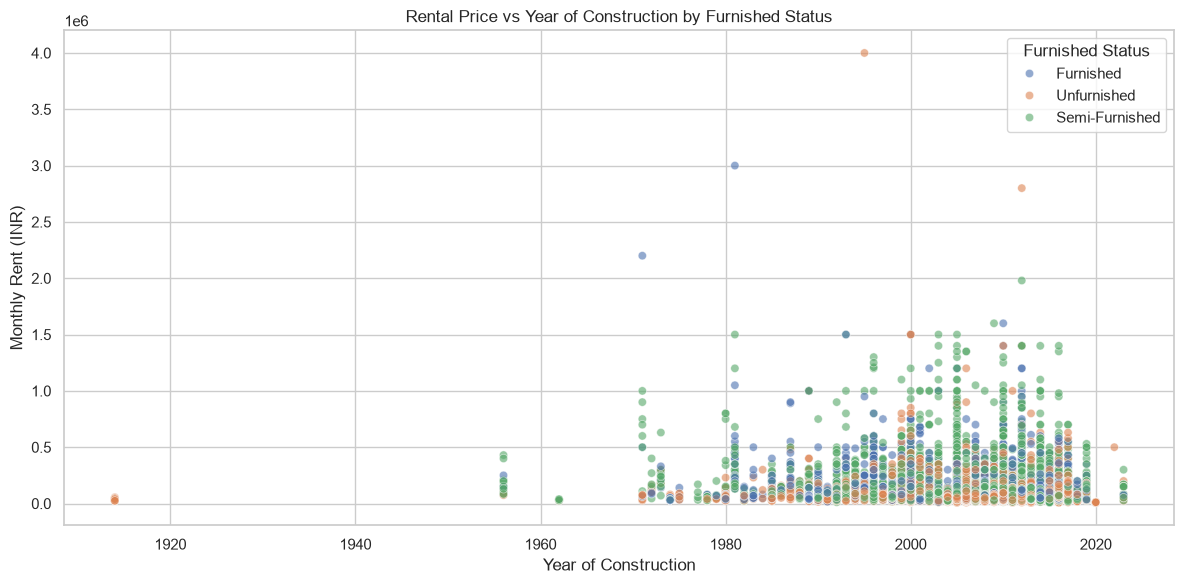

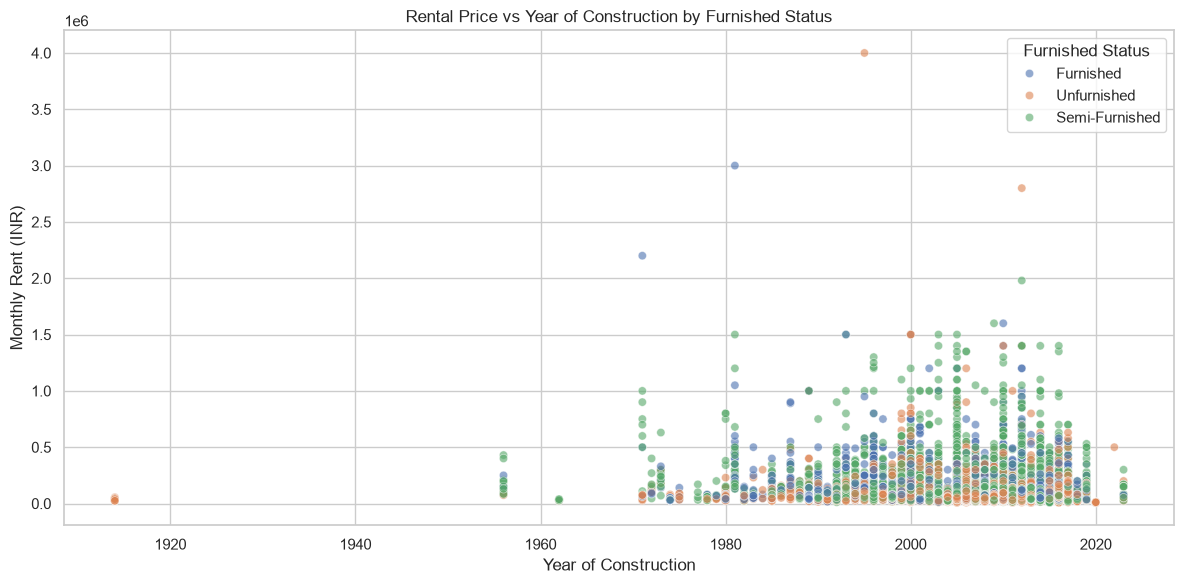

In [17]:
# Select three variables
eda_df = df[["Year of Construction", "Price", "Furnished"]].copy()

# Convert numerical columns
eda_df["Year of Construction"] = pd.to_numeric(
    eda_df["Year of Construction"], errors="coerce"
)
eda_df["Price"] = pd.to_numeric(
    eda_df["Price"], errors="coerce"
)

# Remove missing values
eda_df = eda_df.dropna()

# Create scatter plot
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=eda_df,
    x="Year of Construction",
    y="Price",
    hue="Furnished",
    alpha=0.6
)

plt.title("Rental Price vs Year of Construction by Furnished Status")
plt.xlabel("Year of Construction")
plt.ylabel("Monthly Rent (INR)")
plt.legend(title="Furnished Status")
plt.tight_layout()

# Select three variables
eda_df = df[["Year of Construction", "Price", "Furnished"]].copy()

# Convert numerical columns
eda_df["Year of Construction"] = pd.to_numeric(
    eda_df["Year of Construction"], errors="coerce"
)

eda_df["Price"] = pd.to_numeric(
    eda_df["Price"], errors="coerce"
)

# Remove missing values
eda_df = eda_df.dropna()

# Create scatter plot
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=eda_df,
    x="Year of Construction",
    y="Price",
    hue="Furnished",
    alpha=0.6
)

plt.title("Rental Price vs Year of Construction by Furnished Status")
plt.xlabel("Year of Construction")
plt.ylabel("Monthly Rent (INR)")
plt.legend(title="Furnished Status")
plt.tight_layout()
plt.show()

EDA 06: Most properties in the dataset were constructed/given on rent between 1980 to 2020. The scatter plot reveals a few extreme rental prices, with the highest reaching approximately ₹4,000,000 per month (₹40 lakh) for an unfurnished property constructed around 1995. These unusually high prices may represent data entry errors or inconsistencies in the dataset.

9. Analyzing the impact of number of bedrooms on floor area, and floor area on monthly rent using a scatter plot.

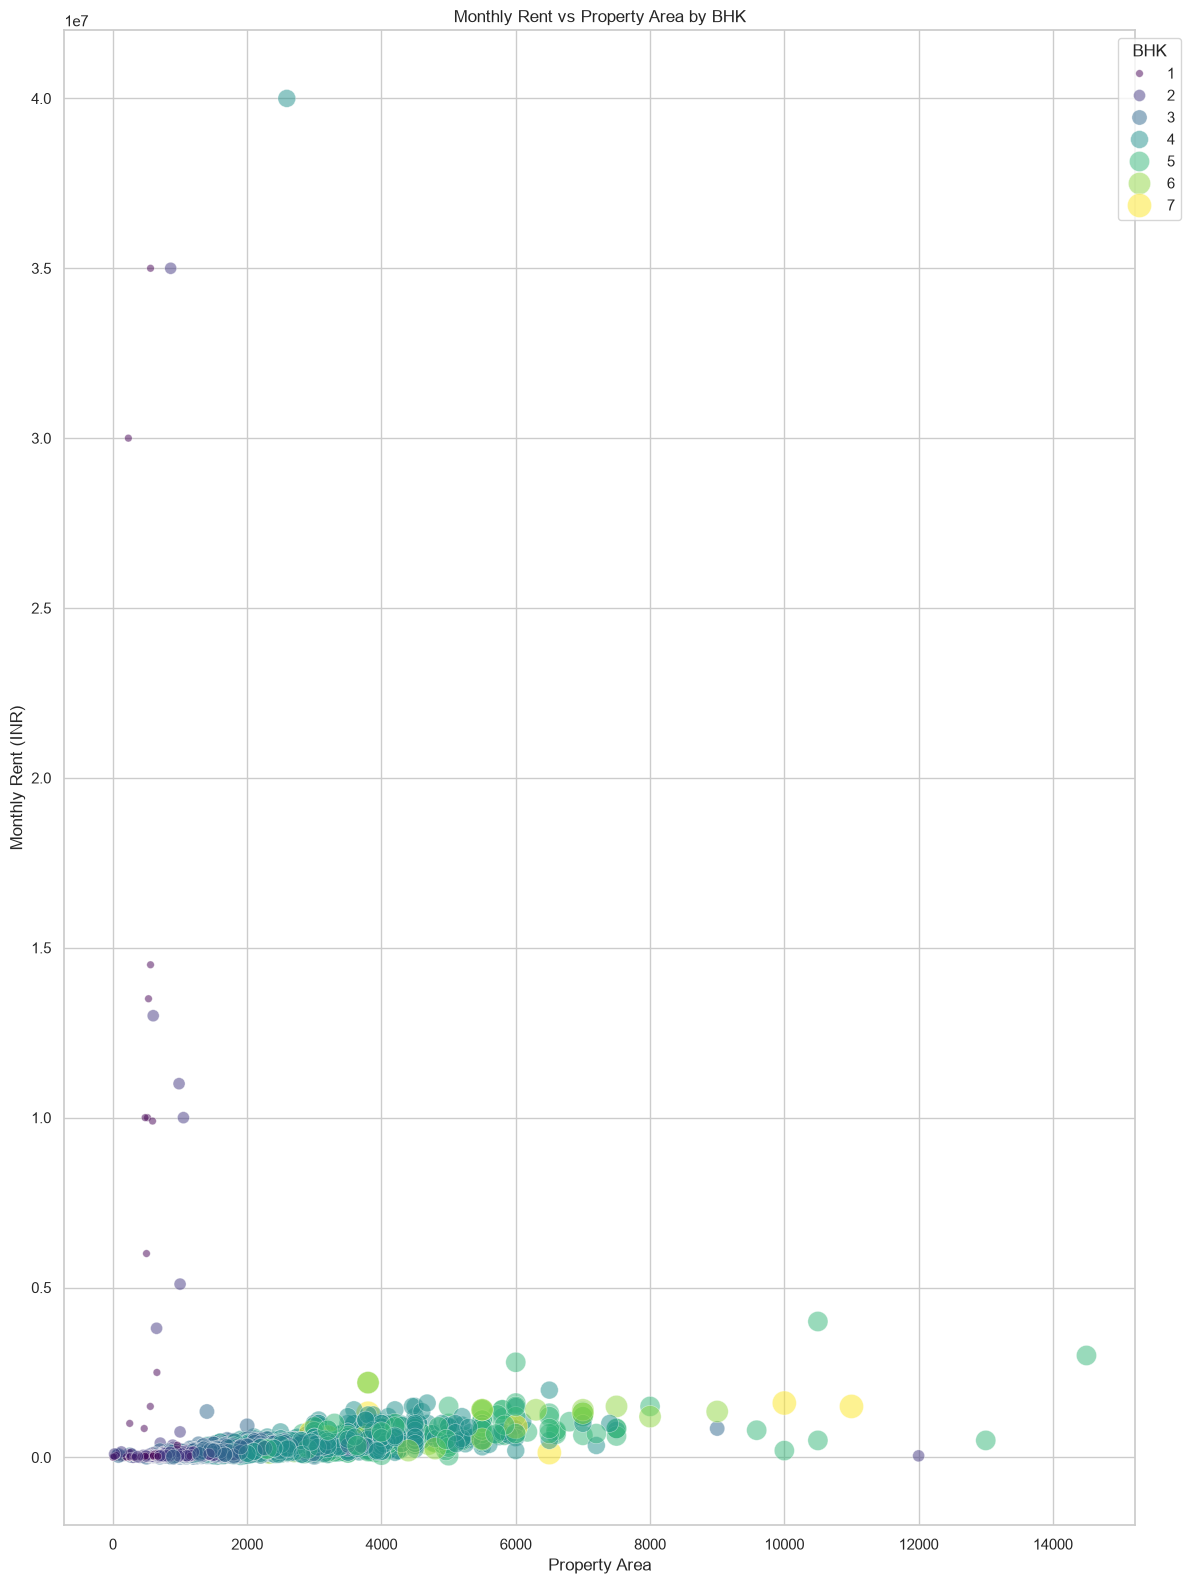

In [25]:
# Select variables
bubble_df = df[["Area", "Price", "BHK"]].copy()

# Convert to numeric
for col in ["Area", "Price", "BHK"]:
    bubble_df[col] = pd.to_numeric(
        bubble_df[col], errors="coerce"
    )

# Remove missing and invalid values
bubble_df = bubble_df.dropna()
bubble_df = bubble_df[
    (bubble_df["Area"] > 0) &
    (bubble_df["Price"] > 0) &
    (bubble_df["BHK"] > 0)
]

# Create bubble chart
plt.figure(figsize=(12, 16))
sns.scatterplot(
    data=bubble_df,
    x="Area",
    y="Price",
    hue="BHK",
    size="BHK",
    sizes=(30, 300),
    palette="viridis",
    alpha=0.5
)

plt.title("Monthly Rent vs Property Area by BHK")
plt.xlabel("Property Area")
plt.ylabel("Monthly Rent (INR)")
plt.legend(title="BHK", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

EDA 07: Larger properties have higher BHK, which is ideal, and also have higher rents. However, some smaller-area with lesser BHK, have extremely high rentals. This may be due to factors like proximity to the sea, locality, economic class, proximity to landmarks/tourist spots, etc. It helps us to understand the unusually high rental prices and understand whether there are any extreme outliers.

10. Analysing the impact of number of balconies and respective floor height with monthly rent using a heat map.

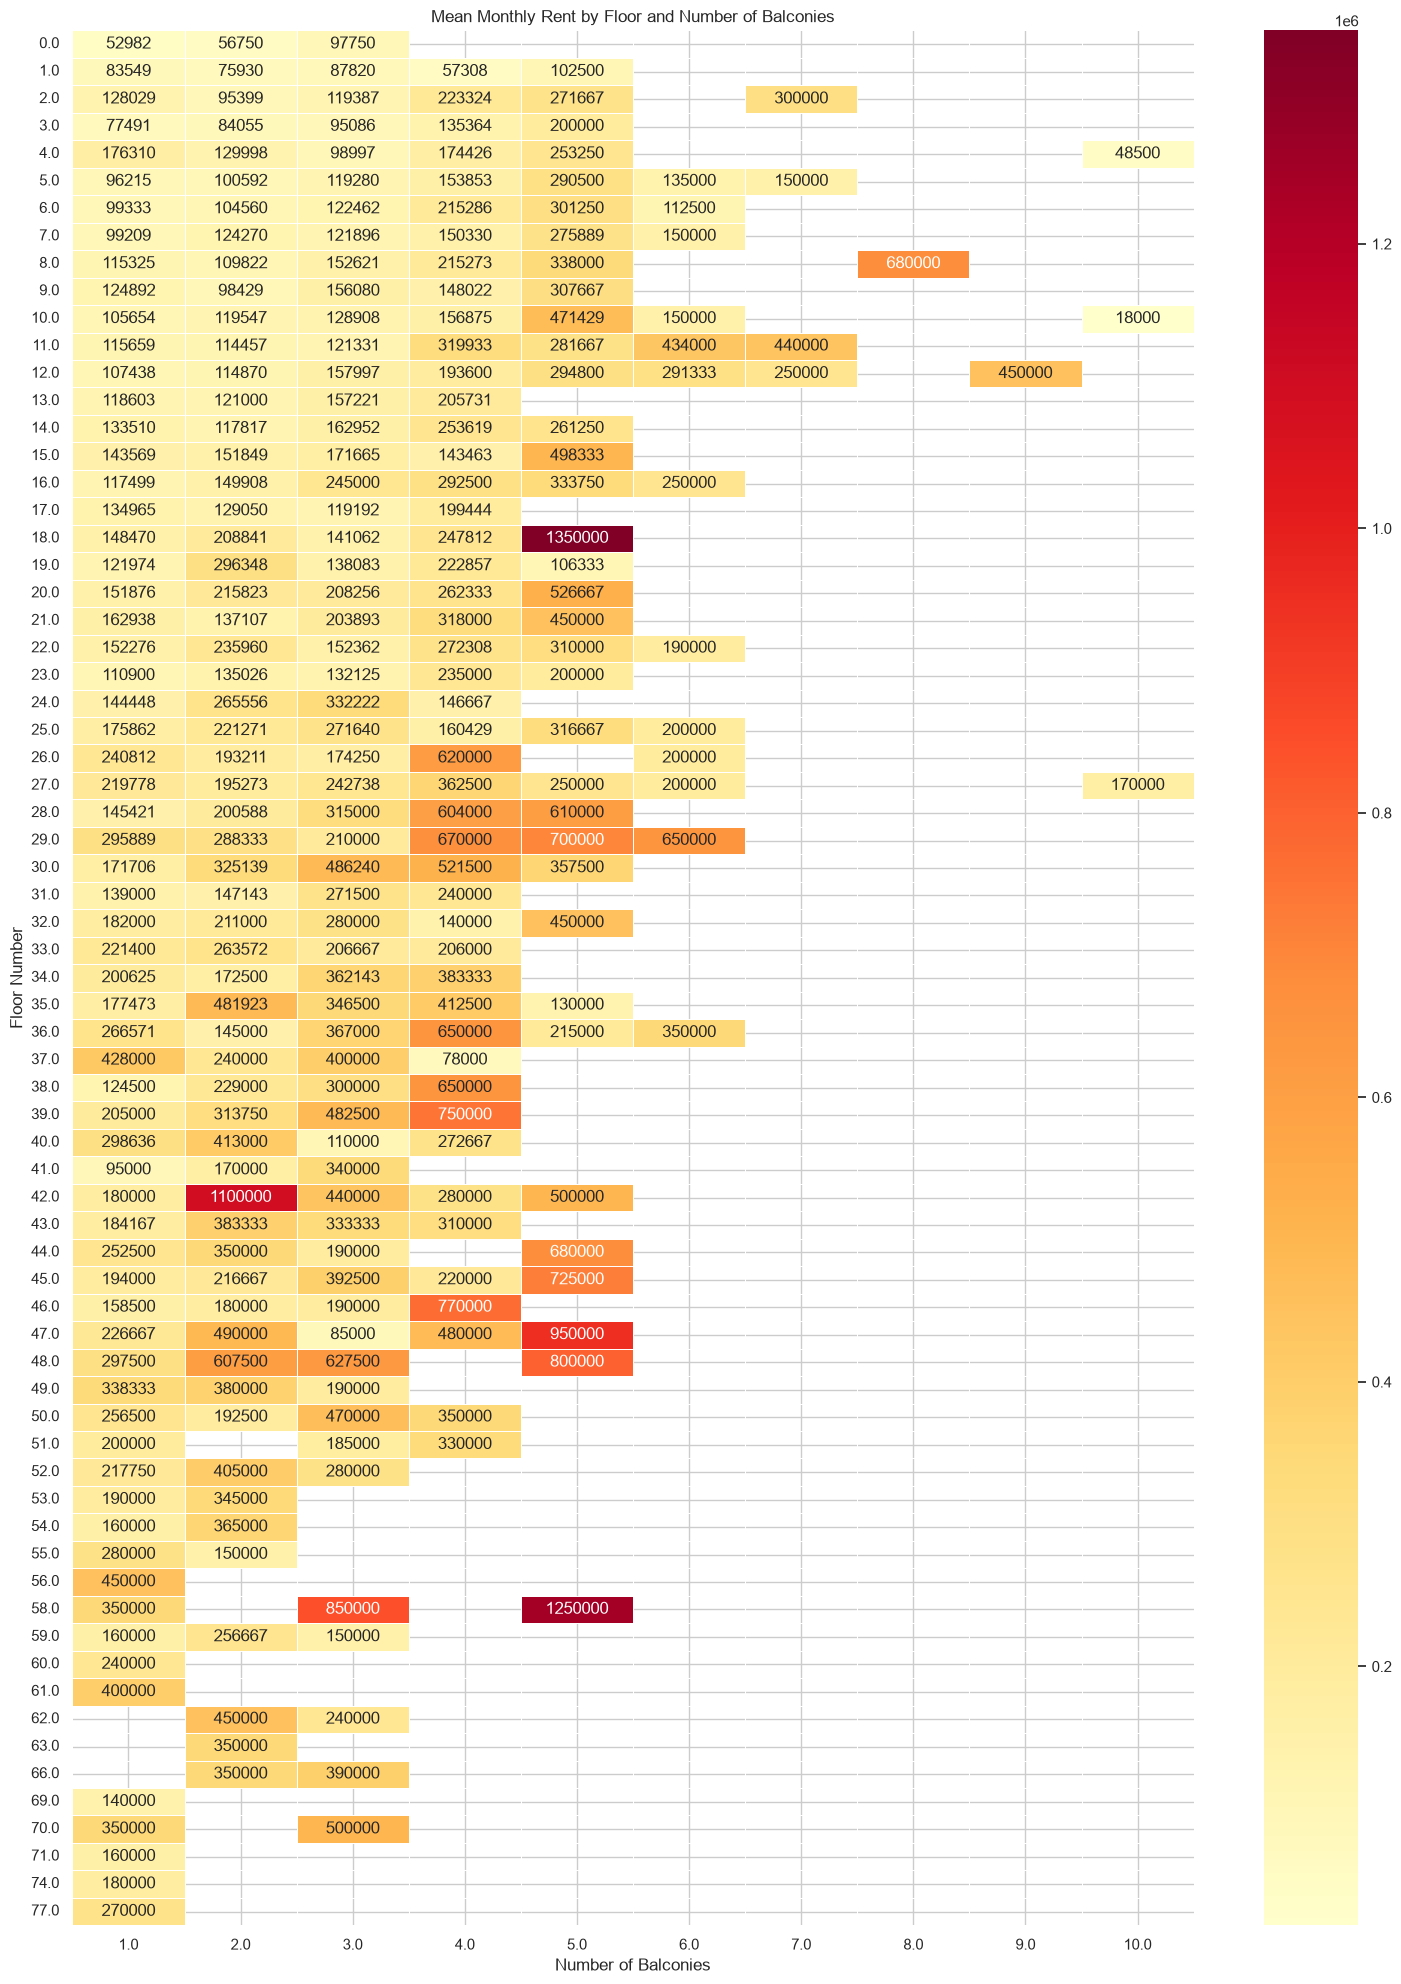

In [29]:
# Select variables
heatmap_df = df[["Floor", "Balconies", "Price"]].copy()

# Convert to numeric
for col in ["Floor", "Balconies", "Price"]:
    heatmap_df[col] = pd.to_numeric(
        heatmap_df[col], errors="coerce"
    )

# Remove missing values
heatmap_df = heatmap_df.dropna()

# Keep valid values
heatmap_df = heatmap_df[
    (heatmap_df["Floor"] >= 0) &
    (heatmap_df["Balconies"] >= 0) &
    (heatmap_df["Price"] > 0)
]

# Calculate mean rent by floor and balconies
heatmap_data = heatmap_df.pivot_table(
    index="Floor",
    columns="Balconies",
    values="Price",
    aggfunc="mean"
)

# Create heatmap
plt.figure(figsize=(15, 20))
sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f",
    linewidths=0.5
)

plt.title("Mean Monthly Rent by Floor and Number of Balconies")
plt.xlabel("Number of Balconies")
plt.ylabel("Floor Number")
plt.tight_layout()
plt.show()

EDA 09: Heat map shows an increase in rental price higher the floor of the property. It also indicated high rent for properties with more balconies. 

11. Analysing if number of bathrooms proportionally vary with number of bedrooms and how this impacts the monthly rent using a bar chart.

,BHK,Bathrooms,mean,count
0,1.0,1.0,7.377566e+04,2461
1,1.0,2.0,5.616532e+04,2185
2,1.0,3.0,6.683333e+04,6
3,1.0,4.0,9.000000e+03,1
4,2.0,1.0,7.281876e+04,222
5,2.0,2.0,8.129754e+04,7730
6,2.0,3.0,1.166970e+05,272
7,2.0,4.0,3.000000e+05,3
8,3.0,1.0,9.968421e+04,19
9,3.0,2.0,1.036889e+05,715


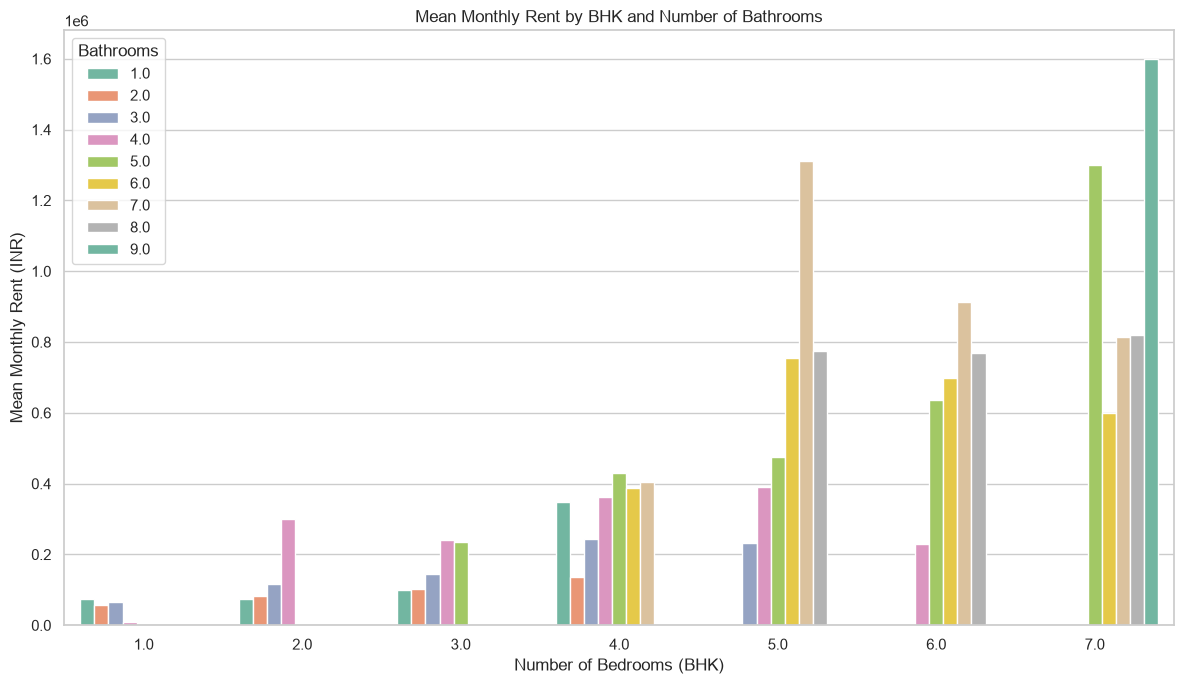

In [32]:
# Select variables
bathroom_df = df[["Price", "BHK", "Bathrooms"]].copy()

# Convert to numeric
for col in ["Price", "BHK", "Bathrooms"]:
    bathroom_df[col] = pd.to_numeric(
        bathroom_df[col], errors="coerce"
    )

# Remove missing and invalid values
bathroom_df = bathroom_df.dropna()
bathroom_df = bathroom_df[
    (bathroom_df["Price"] > 0) &
    (bathroom_df["BHK"] > 0) &
    (bathroom_df["Bathrooms"] > 0)
]

# Calculate mean rental price
bathroom_summary = (
    bathroom_df.groupby(["BHK", "Bathrooms"])["Price"]
    .agg(["mean", "count"])
    .reset_index()
)
display(bathroom_summary)

# Create grouped bar chart
plt.figure(figsize=(12, 7))
sns.barplot(
    data=bathroom_df,
    x="BHK",
    y="Price",
    hue="Bathrooms",
    estimator="mean",
    errorbar=None,
    palette="Set2"
)

plt.title("Mean Monthly Rent by BHK and Number of Bathrooms")
plt.xlabel("Number of Bedrooms (BHK)")
plt.ylabel("Mean Monthly Rent (INR)")
plt.legend(title="Bathrooms")
plt.tight_layout()
plt.show()

EDA 10: Number of bathrooms for the number of bedrooms in a property seem proportional throughout the DataFrame. Monthly rent increases as the number of bathrooms and bedrooms increase in a property. Configurations with higher bedrooms and bathrooms are related to premium pricing tiers.